<a href="https://colab.research.google.com/github/snatzehua/bt-4012-project-2026/blob/feat--zs-exploration-00/06_temporal_stacking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BT4012 · 06 · Temporal stacking

**Question:** can a learned combination of LightGBM, CatBoost and XGBoost improve month-5 fraud ranking compared with individual models and an equal-weight blend?

This tests the stacking idea discussed in the uploaded paper using a chronological development design. It does not attempt to reproduce the paper's reported scores or unspecified split.

A logistic-regression meta-model learns from **out-of-time predictions on months 2–4**, generated by base models trained exclusively on earlier months. Then the base models are refitted on eligible months 0–4 and score month 5. The fitted meta-model combines these month-5 scores without learning from month-5 labels.

**Default:** one seed (42), 13 base fits + one small meta-model fit. First check whether stacking is promising. For a stability run, change `SEEDS` to `[42, 43, 44]` and rerun in a new run directory. Do not select the best individual seed.

Base hyperparameters and 10:1 undersampling were selected in earlier month-5 experiments. Therefore month 5 remains a reused development set, not a fresh unbiased evaluation. Months 6–7 are never loaded for modelling or evaluated here. The meta-model uses a fixed C=1.0; no meta-model hyperparameter search is performed.


## 1. Paths

Run after `00_data_preparation.ipynb`. Reuse `MyDrive/BT4012_grp_proj/processed/` on Colab or `data/processed/` locally. This notebook is standalone; it refits the final models rather than depending on a particular previous artifact directory. Keep it in `notebooks/` locally. Use a CPU runtime.


In [ ]:
import sys
from pathlib import Path

# Detect the runtime; local execution does not require google.colab.
IN_COLAB = 'google.colab' in sys.modules

# Colab: keep Base.csv directly inside this existing Drive project folder.
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/BT4012_grp_proj')

# Local: normally leave None; set an absolute repo path if auto-detection fails.
LOCAL_REPO_ROOT = None

if IN_COLAB:
    from google.colab import drive

    drive.mount('/content/drive')
    PROJECT_DIR = DRIVE_PROJECT_DIR
    RAW_PATH = PROJECT_DIR / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'processed'
else:
    if LOCAL_REPO_ROOT is not None:
        PROJECT_DIR = Path(LOCAL_REPO_ROOT).expanduser().resolve()
    else:
        working_dir = Path.cwd().resolve()
        candidates = [working_dir, *working_dir.parents]
        PROJECT_DIR = next(
            (
                candidate
                for candidate in candidates
                if (candidate / 'notebooks').is_dir()
                and (candidate / 'data').is_dir()
            ),
            working_dir,
        )

    RAW_PATH = PROJECT_DIR / 'data' / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'

CLEAN_PATH = PROCESSED_DIR / 'baf_clean.parquet'
MANIFEST_PATH = PROCESSED_DIR / 'preparation_manifest.json'

print('Runtime:', 'Google Colab' if IN_COLAB else 'Local Python')
print('Project:', PROJECT_DIR)
print('Raw CSV:', RAW_PATH)
print('Prepared data:', CLEAN_PATH)


Mounted at /content/drive
Runtime: Google Colab
Project: /content/drive/MyDrive/BT4012_grp_proj
Raw CSV: /content/drive/MyDrive/BT4012_grp_proj/Base.csv
Prepared data: /content/drive/MyDrive/BT4012_grp_proj/processed/baf_clean.parquet


## 2. Dependencies and fixed configuration

Colab installs missing LightGBM, CatBoost, XGBoost and PyArrow packages. Locally use the same dependencies as notebook 05. Keep the same package versions when comparing or reloading artifacts.

`SEEDS=[42]` is an initial bounded experiment. Full-data LightGBM is included as the original reference. Fold models are discarded after producing out-of-time scores; final base pipelines, the meta-model and predictions are saved. Each execution creates a new directory and checkpoints completed evaluations; automatic restart/resume is not implemented.


In [ ]:
import importlib.util
import subprocess

required_packages = {
    'lightgbm': 'lightgbm>=4.0', 'pyarrow': 'pyarrow>=14.0',
    'catboost': 'catboost>=1.2', 'xgboost': 'xgboost>=2.0',
}
missing_packages = [
    package for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]

if missing_packages:
    if IN_COLAB:
        subprocess.check_call([
            sys.executable, '-m', 'pip', 'install', '-q', *missing_packages,
        ])
    else:
        raise ImportError('Missing dependencies. Run: python -m pip install -r requirements.txt')

import hashlib
import json
import platform
import time
import warnings
from datetime import datetime, timezone
from uuid import uuid4

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
import catboost
import xgboost




SEEDS = [42]
N_JOBS = 2
VERIFY_CHECKSUM = True
SAVE_MODELS = True
FPR_TARGET = 0.05
REVIEW_CAPACITIES = [0.01, 0.02, 0.05]
TRAIN_MONTHS = [0, 1, 2, 3, 4]
VALIDATION_MONTHS = [5]
NEGATIVES_PER_POSITIVE = 10
LGBM_TREES = 300
LOGREG_MAX_ITER = 2000
META_C = 1.0
BASE_ORDER = ['lightgbm', 'catboost', 'xgboost']
BASE_PARAMS = {
    'lightgbm': {'num_leaves': 15, 'min_child_samples': 100},
    'catboost': {'depth': 4, 'iterations': 600},
    'xgboost': {'max_depth': 3, 'n_estimators': 600},
}
FOLDS = [
    {'train_months': [0, 1], 'prediction_month': 2},
    {'train_months': [0, 1, 2], 'prediction_month': 3},
    {'train_months': [0, 1, 2, 3], 'prediction_month': 4},
]
assert len(SEEDS) > 0 and len(SEEDS) == len(set(SEEDS))
run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
RUN_NAME = f'temporal_stack_{run_id}'
RESULTS_DIR = PROJECT_DIR / 'results' / 'temporal_stacking' / RUN_NAME
ARTIFACTS_DIR = PROJECT_DIR / 'artifacts' / 'temporal_stacking' / RUN_NAME
FIGURES_DIR = RESULTS_DIR / 'figures'
for directory in [RESULTS_DIR, ARTIFACTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=False)

plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 200})
print('Results:', RESULTS_DIR)
print('Models/predictions:', ARTIFACTS_DIR)
print('Base-model fits:', len(SEEDS) * (len(FOLDS) * len(BASE_ORDER) + len(BASE_ORDER) + 1))
print('Meta-model fits:', len(SEEDS))


Results: /content/drive/MyDrive/BT4012_grp_proj/results/temporal_stacking/temporal_stack_20261115T195110Z_f62256
Models/predictions: /content/drive/MyDrive/BT4012_grp_proj/artifacts/temporal_stacking/temporal_stack_20261115T195110Z_f62256
Base-model fits: 13
Meta-model fits: 1


## 3. Load development months only

Reuse the preparation schema and training-history constant exclusion. Feature columns exclude target, month and row ID. Each fold fits its own learned preprocessing. The shared feature list was established in earlier preparation, so this is not a fully nested feature-selection backtest.


In [ ]:
def file_sha256(path):
    """Return a chunked SHA-256 digest to verify the prepared file matches its manifest."""
    digest = hashlib.sha256()

    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)

    return digest.hexdigest()


if not CLEAN_PATH.is_file() or not MANIFEST_PATH.is_file():
    raise FileNotFoundError('Run 00_data_preparation.ipynb first with the same project paths.')

with open(MANIFEST_PATH, encoding='utf-8') as handle:
    manifest = json.load(handle)

if manifest.get('schema_version') != 1:
    raise ValueError('Unsupported preparation manifest version.')

if VERIFY_CHECKSUM and file_sha256(CLEAN_PATH) != manifest['prepared_sha256']:
    raise ValueError('Parquet fingerprint differs from the manifest; rerun preparation.')


TARGET = manifest['target']
MONTH = manifest['month_column']
ROW_ID = manifest['row_id_column']
FEATURES = manifest['features']
NUMERICAL = manifest['numerical_features']
CATEGORICAL = manifest['categorical_features']

if manifest['split_months']['train'] != TRAIN_MONTHS:
    raise ValueError('This experiment expects training months 0–4.')

if manifest['split_months']['validation'] != VALIDATION_MONTHS:
    raise ValueError('This experiment expects validation month 5.')

if set(FEATURES) != set(NUMERICAL + CATEGORICAL):
    raise ValueError('Inconsistent feature lists in preparation manifest.')

if set(FEATURES) & {TARGET, MONTH, ROW_ID}:
    raise ValueError('Target, month or row ID cannot be predictors.')

df = pd.read_parquet(
    CLEAN_PATH,
    filters=[(MONTH, 'in', TRAIN_MONTHS + VALIDATION_MONTHS)],
)

if list(df.columns) != manifest['columns'] or not df[ROW_ID].is_unique:
    raise ValueError('Prepared schema or row identifiers are inconsistent.')

for column in CATEGORICAL:
    df[column] = df[column].astype(object).where(df[column].notna(), np.nan)

# Sort by original row ID to make sampling reproducible if parquet row order changes.
history = df[df[MONTH].isin(TRAIN_MONTHS)].sort_values(ROW_ID).reset_index(drop=True)
validation = df[df[MONTH].isin(VALIDATION_MONTHS)].sort_values(ROW_ID).reset_index(drop=True)
del df

for name, frame in [('train', history), ('validation', validation)]:
    if len(frame) != manifest['split_counts'][name]:
        raise ValueError(f'{name} row count differs from the preparation manifest.')

    if not frame[TARGET].isin([0, 1]).all() or frame[TARGET].nunique() != 2:
        raise ValueError(f'{name} must contain valid labels and both classes.')

X_validation = validation[FEATURES]
y_validation = validation[TARGET].to_numpy()
validation_ties = np.random.default_rng(2026).random(len(validation))

display(history.groupby(MONTH)[TARGET].agg(
    applications='size', frauds='sum', fraud_rate='mean',
))
print('Validation applications:', len(validation))
print('Validation frauds:', int(y_validation.sum()))
print('Predictors:', len(FEATURES))


,applications,frauds,fraud_rate
month,,,
0,132440,1500,0.011326
1,127620,1198,0.009387
2,136979,1198,0.008746
3,150936,1392,0.009222
4,127691,1452,0.011371


Validation applications: 119323
Validation frauds: 1411
Predictors: 29


## 4. Forward folds and sampling

| Fold | Base-model training months | Out-of-time prediction month |
|---|---|---|
| 1 | 0–1 | 2 |
| 2 | 0–2 | 3 |
| 3 | 0–3 | 4 |

For each training fold, retain every fraud and uniformly sample ten legitimate applications per fraud. Every base family receives the same retained rows within that fold and seed. The prediction month is **not undersampled**: retain all applications and the natural class prevalence for meta-model training.

There are no out-of-time scores for months 0–1, so those rows do not train the meta-model. They still train the base models. Fold 1 starts with two months to avoid building the meta-model around an especially small warm-up fit. We assume historical labels are available by the next month; the dataset does not provide label-arrival timestamps to model investigation delays.


In [ ]:
def sample_training(frame, seed):
    """Return all frauds plus a reproducible 10:1 negative sample from eligible rows.

    Sort by row ID before sampling so identical eligible data and seed reproduce
    Stage B/C's random-negative permutation even if dataframe order changes.
    """
    frame = frame.sort_values(ROW_ID).reset_index(drop=True)
    positive = np.flatnonzero(frame[TARGET].to_numpy() == 1)
    negative = np.flatnonzero(frame[TARGET].to_numpy() == 0)
    n_negative = NEGATIVES_PER_POSITIVE * len(positive)
    if len(positive) == 0 or n_negative > len(negative):
        raise ValueError('Eligible fold cannot support the requested 10:1 sample.')
    shuffled = np.random.default_rng(seed).permutation(negative)
    positions = np.concatenate([positive, shuffled[:n_negative]])
    sampled = frame.iloc[positions].sort_values(ROW_ID)
    assert sampled[ROW_ID].is_unique
    assert int(sampled[TARGET].sum()) == len(positive)
    return sampled


for fold in FOLDS:
    assert max(fold['train_months']) < fold['prediction_month']
    assert set(fold['train_months']) <= set(TRAIN_MONTHS)
    assert fold['prediction_month'] in TRAIN_MONTHS

display(pd.DataFrame(FOLDS))


,train_months,prediction_month
0,"[0, 1]",2
1,"[0, 1, 2]",3
2,"[0, 1, 2, 3]",4


## 5. Reuse the Stage C base pipelines

LightGBM uses numeric NaNs and training-fitted categorical codes explicitly marked categorical. CatBoost uses numeric NaNs and categorical strings with a missing-category label. XGBoost uses numeric NaNs and dense one-hot categories, preserving explicit zeros. Every fold creates fresh preprocessing.

No weighting or early stopping is applied. The selected settings are fixed before this run. Model-family differences are intentional; no external target encoding or original features are passed to the meta-model.


In [ ]:
def build_model(model_name, params, seed):
    """
    Build an unfitted model with preprocessing appropriate to its model family.

    Process:
    1. Define transformations without fitting any training statistics.
    2. Combine numeric/categorical transformations in a ColumnTransformer.
    3. Attach an unweighted classifier.

    Returns:
        Tuple: the estimator and additional fit arguments. LightGBM needs the
        transformed categorical column positions explicitly marked at fit time.
    """
    if model_name == 'logreg':
        numeric_pipeline = Pipeline([
            ('impute', SimpleImputer(
                strategy='median',
                add_indicator=True,
                keep_empty_features=True,
            )),
            ('scale', StandardScaler()),
        ])

        categorical_pipeline = Pipeline([
            ('impute', SimpleImputer(
                strategy='constant',
                fill_value='__MISSING__',
                keep_empty_features=True,
            )),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=True)),
        ])

        preprocessing = ColumnTransformer(
            transformers=[
                ('numeric', numeric_pipeline, NUMERICAL),
                ('categorical', categorical_pipeline, CATEGORICAL),
            ],
            sparse_threshold=1.0,
        )

        classifier = LogisticRegression(
            C=params['C'],
            solver='lbfgs',
            max_iter=LOGREG_MAX_ITER,
            class_weight=None,
            random_state=seed,
        )

        return Pipeline([
            ('preprocessing', preprocessing),
            ('classifier', classifier),
        ]), {}

    if model_name == 'lightgbm':
        categorical_pipeline = Pipeline([
            ('impute', SimpleImputer(
                strategy='constant',
                fill_value='__MISSING__',
                keep_empty_features=True,
            )),
            ('encode', OrdinalEncoder(
                handle_unknown='use_encoded_value',
                unknown_value=-1,
                dtype=np.int32,
            )),
        ])

        # ColumnTransformer puts numeric columns first and category codes second.
        preprocessing = ColumnTransformer([
            ('numeric', 'passthrough', NUMERICAL),
            ('categorical', categorical_pipeline, CATEGORICAL),
        ])

        classifier = LGBMClassifier(
            objective='binary',
            n_estimators=LGBM_TREES,
            learning_rate=0.05,
            num_leaves=params['num_leaves'],
            min_child_samples=params['min_child_samples'],
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            class_weight=None,
            scale_pos_weight=1.0,
            random_state=seed,
            n_jobs=N_JOBS,
            verbosity=-1,
        )

        categorical_positions = list(range(
            len(NUMERICAL), len(NUMERICAL) + len(CATEGORICAL),
        ))

        return Pipeline([
            ('preprocessing', preprocessing),
            ('classifier', classifier),
        ]), {'classifier__categorical_feature': categorical_positions}


    if model_name == 'xgboost':
        categorical_pipeline = Pipeline([
            ('impute', SimpleImputer(
                strategy='constant', fill_value='__MISSING__', keep_empty_features=True,
            )),
            ('encode', OneHotEncoder(
                handle_unknown='ignore', sparse_output=False, dtype=np.float32,
            )),
        ])
        preprocessing = ColumnTransformer([
            ('numeric', 'passthrough', NUMERICAL),
            ('categorical', categorical_pipeline, CATEGORICAL),
        ], sparse_threshold=0)
        classifier = XGBClassifier(
            objective='binary:logistic', tree_method='hist',
            n_estimators=params['n_estimators'], max_depth=params['max_depth'],
            learning_rate=0.05, min_child_weight=5,
            subsample=0.8, colsample_bytree=0.8,
            reg_lambda=1.0, reg_alpha=0.0, scale_pos_weight=1.0,
            eval_metric='logloss', random_state=seed, n_jobs=N_JOBS,
        )
        return Pipeline([
            ('preprocessing', preprocessing), ('classifier', classifier),
        ]), {}

    if model_name == 'catboost':
        preprocessing = ColumnTransformer([
            ('numeric', 'passthrough', NUMERICAL),
            ('categorical', SimpleImputer(
                strategy='constant', fill_value='__MISSING__', keep_empty_features=True,
            ), CATEGORICAL),
        ])
        categorical_positions = list(range(
            len(NUMERICAL), len(NUMERICAL) + len(CATEGORICAL),
        ))
        classifier = CatBoostClassifier(
            loss_function='Logloss', iterations=params['iterations'],
            depth=params['depth'], learning_rate=0.05, l2_leaf_reg=3.0,
            boosting_type='Plain', task_type='CPU',
            cat_features=categorical_positions, random_seed=seed,
            thread_count=N_JOBS, verbose=False, allow_writing_files=False,
        )
        return Pipeline([
            ('preprocessing', preprocessing), ('classifier', classifier),
        ]), {}

    raise ValueError(f'Unknown model: {model_name}')


## 6. Metrics and checkpoint helpers

AP remains primary. Each candidate receives its own month-5 threshold satisfying empirical FPR ≤5%. Review budgets select exact top-K rows using identical label-independent tie breakers. These validation-selected cutoffs do not guarantee future FPR.

The meta-model and equal-weight blend are evaluated exactly like the individual classifiers. A constant 0.5 cutoff is never used to claim an improvement. The full-data and undersampled scores have different scales; all reported thresholds belong to the named fitted scoring system.


In [ ]:
def at_threshold(y_true, scores, threshold):
    """
    Return confusion counts and operating metrics at an unchanged score cutoff.
    A score equal to the cutoff is flagged; divisions with zero denominators return 0.
    """
    flagged = np.asarray(scores) >= threshold
    positive = np.asarray(y_true) == 1

    tp = int(np.sum(flagged & positive))
    fp = int(np.sum(flagged & ~positive))
    fn = int(np.sum(~flagged & positive))
    tn = int(np.sum(~flagged & ~positive))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    return {
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'tn': tn,
        'precision': precision,
        'recall': recall,
        'f1': 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        'fpr': fp / (fp + tn) if fp + tn else 0.0,
        'alert_rate': float(flagged.mean()),
    }


def threshold_for_fpr(y_true, scores, target_fpr):
    """
    Choose the least restrictive empirical cutoff satisfying an FPR ceiling.

    Evaluate every distinct ROC threshold on the supplied labeled split. This is
    deployable when supplied validation labels; using test labels instead defines
    a retrospective benchmark and must not be confused with a deployment threshold.
    """
    fpr, _, thresholds = roc_curve(y_true, scores, drop_intermediate=False)
    eligible = np.flatnonzero(fpr <= target_fpr)

    return float(thresholds[eligible[-1]])


def capacity_table(y_true, scores, capacities, tie_breakers):
    """
    Evaluate fraud captured when only an exact top-scoring budget is reviewed.

    Rank by descending score, then a label-independent tie breaker. Return review
    counts, precision, recall and true/false positives standardized per 10,000 apps.
    """
    y_true = np.asarray(y_true)
    order = np.lexsort((tie_breakers, -np.asarray(scores)))
    rows = []

    for capacity in capacities:
        n_review = int(np.floor(capacity * len(y_true)))
        reviewed_labels = y_true[order[:n_review]]
        tp = int(reviewed_labels.sum())
        fp = n_review - tp
        total_frauds = int(y_true.sum())

        rows.append({
            'capacity': capacity,
            'reviews': n_review,
            'precision': tp / n_review if n_review else 0.0,
            'recall': tp / total_frauds if total_frauds else 0.0,
            'frauds_flagged': tp,
            'legitimate_reviewed': fp,
            'frauds_missed': total_frauds - tp,
            'frauds_flagged_per_10000': 10000 * tp / len(y_true),
            'legitimate_reviewed_per_10000': 10000 * fp / len(y_true),
        })

    return pd.DataFrame(rows)


def ranking_metrics(y_true, scores, model_name):
    """Return ranking metrics; recall-at-FPR uses labels from this evaluation split."""
    recall_at_fpr = np.nan

    if model_name != 'dummy':
        benchmark_threshold = threshold_for_fpr(y_true, scores, FPR_TARGET)
        recall_at_fpr = at_threshold(y_true, scores, benchmark_threshold)['recall']

    return {
        'average_precision': float(average_precision_score(y_true, scores)),
        'roc_auc': float(roc_auc_score(y_true, scores)),
        'recall_at_target_fpr_benchmark': recall_at_fpr,
    }


In [ ]:
def json_safe(value):
    """
    Convert nested results into standards-compliant JSON values.
    Nonfinite floats become null; threshold direction is recorded separately below.
    """
    if isinstance(value, dict):
        return {key: json_safe(item) for key, item in value.items()}

    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]

    if isinstance(value, (float, np.floating)) and not np.isfinite(value):
        return None

    if isinstance(value, np.generic):
        return value.item()

    return value



def write_json(filename, payload):
    """Write JSON with explicit nulls for nonfinite numeric values."""
    with open(RESULTS_DIR / filename, 'w', encoding='utf-8') as handle:
        json.dump(json_safe(payload), handle, indent=2, allow_nan=False)




run_info = {
    'run_name': RUN_NAME, 'status': 'running', 'seeds': SEEDS,
    'preparation_id': manifest['preparation_id'],
    'prepared_sha256': manifest['prepared_sha256'],
    'base_order': BASE_ORDER, 'base_params': BASE_PARAMS,
    'folds': FOLDS, 'sampling_negative_positive_ratio': NEGATIVES_PER_POSITIVE,
    'meta_input': 'three raw positive-class base scores, StandardScaler, LogisticRegression',
    'meta_C': META_C, 'meta_class_weight': None,
    'selection_metric': 'validation average precision',
    'fpr_target': FPR_TARGET, 'review_capacities': REVIEW_CAPACITIES,
    'validation_months': VALIDATION_MONTHS, 'test_evaluated': False,
    'n_jobs': N_JOBS, 'save_models': SAVE_MODELS,
    'versions': {
        'python': platform.python_version(), 'pandas': pd.__version__,
        'numpy': np.__version__, 'sklearn': sklearn.__version__,
        'lightgbm': lightgbm.__version__, 'catboost': catboost.__version__,
        'xgboost': xgboost.__version__, 'joblib': joblib.__version__,
    },
}
write_json('run_info.json', run_info)
write_json('preparation_manifest.json', manifest)
validation[[ROW_ID, MONTH, TARGET]].to_parquet(
    ARTIFACTS_DIR / 'validation_index.parquet', index=False,
)
fit_records = []
metric_rows = []
capacity_frames = []
coefficient_rows = []
seed_manifests = []


def fit_base(family, frame, seed, stage):
    """Fit a fresh base pipeline and record runtime, rows, settings and warnings."""
    estimator, fit_arguments = build_model(family, BASE_PARAMS[family], seed)
    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        estimator.fit(frame[FEATURES], frame[TARGET], **fit_arguments)
    seconds = time.perf_counter() - start
    messages = list(dict.fromkeys(str(w.message) for w in caught))
    for message in messages:
        print(f'WARNING [{family}/{stage}]: {message}')
    fit_records.append({
        'seed': seed, 'stage': stage, 'family': family,
        'training_rows': len(frame), 'training_frauds': int(frame[TARGET].sum()),
        'fit_seconds': seconds, 'warnings': json.dumps(messages),
        'training_ids_sha256': hashlib.sha256(
            frame[ROW_ID].to_numpy(dtype='<i8').tobytes()
        ).hexdigest(),
        'params': json.dumps(estimator.named_steps['classifier'].get_params(), default=str),
    })
    pd.DataFrame(fit_records).to_csv(RESULTS_DIR / 'fit_log.csv', index=False)
    print(f'{family} | {stage} | seed={seed} | rows={len(frame):,} | {seconds:.1f}s')
    return estimator


def positive_scores(estimator, features):
    """Select class-1 scores explicitly and reject invalid output."""
    positions = np.flatnonzero(np.asarray(estimator.classes_) == 1)
    if len(positions) != 1:
        raise ValueError('Expected exactly one positive-class probability column.')
    scores = estimator.predict_proba(features)[:, positions[0]]
    if not np.isfinite(scores).all():
        raise ValueError('Nonfinite model scores.')
    return scores


def evaluate_scores(name, seed, scores):
    """Evaluate and persist one scoring system on untouched month-5 rows."""
    cutoff = threshold_for_fpr(y_validation, scores, FPR_TARGET)
    operating = at_threshold(y_validation, scores, cutoff)
    assert operating['fpr'] <= FPR_TARGET + 1e-12
    record = {
        'candidate': name, 'seed': seed,
        **ranking_metrics(y_validation, scores, name),
        **{f'at_fpr_{key}': value for key, value in operating.items()},
        'validation_threshold': cutoff,
        'threshold_is_positive_infinity': bool(np.isposinf(cutoff)),
    }
    metric_rows.append(record)
    capacity = capacity_table(y_validation, scores, REVIEW_CAPACITIES, validation_ties)
    capacity.insert(0, 'seed', seed)
    capacity.insert(0, 'candidate', name)
    capacity_frames.append(capacity)
    predictions = validation[[ROW_ID, MONTH, TARGET]].copy()
    predictions['score'] = scores
    predictions.to_parquet(
        ARTIFACTS_DIR / f'{name}_seed_{seed}_validation.parquet', index=False,
    )
    pd.DataFrame(metric_rows).to_csv(RESULTS_DIR / 'validation_metrics.csv', index=False)
    pd.concat(capacity_frames).to_csv(RESULTS_DIR / 'validation_capacity.csv', index=False)
    print(f'{name}: AP={record["average_precision"]:.5f}, recall@5%FPR={operating["recall"]:.3%}')
    return record


## 7. Generate out-of-time scores, fit the meta-model and evaluate

The meta-model has only **three inputs**: the base models' positive-class scores in `BASE_ORDER`. A StandardScaler and regularised logistic regression (`C=1`, no class weighting) are fitted to all natural-prevalence rows from prediction months 2–4. No month-5 label or score is used to fit this meta-model.

Coefficients may be negative because the meta-model learns a conditional combination of correlated scores. They are not voting percentages, causal explanations or original-feature importance. The output is not guaranteed calibrated on future data.

**Distribution mismatch to acknowledge:** out-of-time scores come from models with less history than the final refits. Although all base models use the same sampling ratio, their score distributions can change as training history expands. This is a limitation of this temporal stack, not something to correct using held-out labels.


In [ ]:
for seed in SEEDS:
    oot_frames = []
    fold_summary = []

    for fold_index, fold in enumerate(FOLDS, start=1):
        eligible = history[history[MONTH].isin(fold['train_months'])]
        prediction_frame = history[history[MONTH] == fold['prediction_month']]
        sampled = sample_training(eligible, seed)
        assert sampled[MONTH].max() < prediction_frame[MONTH].min()
        assert not sampled[ROW_ID].isin(prediction_frame[ROW_ID]).any()

        sampled[[ROW_ID]].to_parquet(
            ARTIFACTS_DIR / f'fold_{fold_index}_seed_{seed}_train_ids.parquet', index=False,
        )
        oot = prediction_frame[[ROW_ID, MONTH, TARGET]].copy()
        for family in BASE_ORDER:
            estimator = fit_base(family, sampled, seed, f'fold_{fold_index}')
            oot[family] = positive_scores(estimator, prediction_frame[FEATURES])
            del estimator

        oot_frames.append(oot)
        fold_summary.append({
            'fold': fold_index, 'seed': seed, **fold,
            'eligible_rows': len(eligible), 'retained_training_rows': len(sampled),
            'prediction_rows': len(prediction_frame),
            'prediction_fraud_rate': float(prediction_frame[TARGET].mean()),
        })

    oot = pd.concat(oot_frames, ignore_index=True).sort_values(ROW_ID).reset_index(drop=True)
    expected = history[history[MONTH].isin([fold['prediction_month'] for fold in FOLDS])]
    assert oot[ROW_ID].is_unique and set(oot[ROW_ID]) == set(expected[ROW_ID])
    assert oot[TARGET].nunique() == 2 and not oot[BASE_ORDER].isna().any().any()
    oot.to_parquet(ARTIFACTS_DIR / f'out_of_time_scores_seed_{seed}.parquet', index=False)
    pd.DataFrame(fold_summary).to_csv(RESULTS_DIR / f'fold_summary_seed_{seed}.csv', index=False)

    meta_model = Pipeline([
        ('scale', StandardScaler()),
        ('classifier', LogisticRegression(
            C=META_C, solver='lbfgs', max_iter=LOGREG_MAX_ITER,
            class_weight=None, random_state=seed,
        )),
    ])
    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        meta_model.fit(oot[BASE_ORDER], oot[TARGET])
    meta_fit_seconds = time.perf_counter() - start
    meta_warnings = list(dict.fromkeys(str(w.message) for w in caught))
    for message in meta_warnings:
        print('META WARNING:', message)
    if any(issubclass(w.category, ConvergenceWarning) for w in caught):
        raise RuntimeError('Meta-model did not converge; inspect before interpreting results.')

    for family, coefficient in zip(BASE_ORDER, meta_model.named_steps['classifier'].coef_[0]):
        coefficient_rows.append({'seed': seed, 'base_family': family,
                                 'standardized_score_coefficient': float(coefficient)})

    # Final base fits use all eligible history before applying the 10:1 sample.
    sampled_history = sample_training(history, seed)
    sampled_history[[ROW_ID]].to_parquet(
        ARTIFACTS_DIR / f'final_seed_{seed}_train_ids.parquet', index=False,
    )
    base_validation = validation[[ROW_ID, MONTH, TARGET]].copy()
    final_models = {}
    base_files = {}
    final_fit_seconds = {}

    for family in BASE_ORDER:
        estimator = fit_base(family, sampled_history, seed, 'final_rus10')
        base_validation[family] = positive_scores(estimator, X_validation)
        final_models[family] = estimator
        final_fit_seconds[family] = fit_records[-1]['fit_seconds']
        filename = f'{family}_rus10_seed_{seed}.joblib'
        base_files[family] = filename if SAVE_MODELS else None
        if SAVE_MODELS:
            joblib.dump(estimator, ARTIFACTS_DIR / filename, compress=3)

    full_reference = fit_base('lightgbm', history, seed, 'final_full_reference')
    full_scores = positive_scores(full_reference, X_validation)
    if SAVE_MODELS:
        joblib.dump(full_reference, ARTIFACTS_DIR / f'lightgbm_full_seed_{seed}.joblib', compress=3)
        joblib.dump(meta_model, ARTIFACTS_DIR / f'meta_model_seed_{seed}.joblib', compress=3)

    base_validation.to_parquet(
        ARTIFACTS_DIR / f'base_validation_scores_seed_{seed}.parquet', index=False,
    )
    stack_scores = positive_scores(meta_model, base_validation[BASE_ORDER])
    mean_scores = base_validation[BASE_ORDER].mean(axis=1).to_numpy()

    # Fixed simple blend is a diagnostic control for the value of learning weights.
    seed_records = [evaluate_scores('lightgbm_full', seed, full_scores)]
    for family in BASE_ORDER:
        seed_records.append(evaluate_scores(family + '_rus10', seed, base_validation[family].to_numpy()))
    seed_records.append(evaluate_scores('equal_weight_blend', seed, mean_scores))
    seed_records.append(evaluate_scores('temporal_stack', seed, stack_scores))

    # Verify saved complete pipelines reproduce scores before discarding in-memory fits.
    if SAVE_MODELS:
        reloaded_features = pd.DataFrame(index=validation.index)
        for family in BASE_ORDER:
            restored = joblib.load(ARTIFACTS_DIR / base_files[family])
            reloaded_features[family] = positive_scores(restored, X_validation)
        restored_meta = joblib.load(ARTIFACTS_DIR / f'meta_model_seed_{seed}.joblib')
        reloaded_scores = positive_scores(restored_meta, reloaded_features[BASE_ORDER])
        np.testing.assert_allclose(reloaded_scores, stack_scores, rtol=1e-8, atol=1e-10)

    seed_manifests.append({
        'seed': seed, 'base_models': base_files,
        'meta_model': f'meta_model_seed_{seed}.joblib' if SAVE_MODELS else None,
        'meta_feature_order': BASE_ORDER,
        'meta_input': 'raw positive-class scores, no extra transformation before saved pipeline',
        'meta_training_months': [2, 3, 4], 'meta_training_rows': len(oot),
        'meta_training_prevalence': float(oot[TARGET].mean()),
        'meta_fit_seconds': meta_fit_seconds, 'meta_warnings': meta_warnings,
        'meta_intercept': float(meta_model.named_steps['classifier'].intercept_[0]),
        'final_base_fit_seconds': final_fit_seconds,
        'evaluation': seed_records,
    })
    write_json('stack_models.json', seed_manifests)
    pd.DataFrame(coefficient_rows).to_csv(RESULTS_DIR / 'meta_coefficients.csv', index=False)
    del final_models, full_reference, meta_model, oot


lightgbm | fold_1 | seed=42 | rows=29,678 | 5.4s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


catboost | fold_1 | seed=42 | rows=29,678 | 20.6s
xgboost | fold_1 | seed=42 | rows=29,678 | 1.7s
lightgbm | fold_2 | seed=42 | rows=42,856 | 1.2s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


catboost | fold_2 | seed=42 | rows=42,856 | 19.9s
xgboost | fold_2 | seed=42 | rows=42,856 | 2.1s
lightgbm | fold_3 | seed=42 | rows=58,168 | 2.5s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (2 outputs left out)

catboost | final_rus10 | seed=42 | rows=74,140 | 32.6s
xgboost | final_rus10 | seed=42 | rows=74,140 | 3.6s
lightgbm | final_full_reference | seed=42 | rows=675,666 | 20.0s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


lightgbm_full: AP=0.18499, recall@5%FPR=54.500%
lightgbm_rus10: AP=0.19147, recall@5%FPR=53.650%
catboost_rus10: AP=0.19725, recall@5%FPR=54.571%
xgboost_rus10: AP=0.19226, recall@5%FPR=54.288%
equal_weight_blend: AP=0.19691, recall@5%FPR=54.217%
temporal_stack: AP=0.19784, recall@5%FPR=54.571%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## 8. Compare against both individual models and the fixed blend

The important contrasts are stack versus CatBoost (the previous AP winner), versus unweighted full-data LightGBM (the recall reference), and versus the equal-weight blend (does learning the combination help?). All are evaluated on exactly the same month-5 rows.

With one seed, SD is undefined and displayed as NaN. Do not interpret zero-width chart error bars as certainty. With multiple seeds, report paired differences; mean seed metrics are not predictions from a seed ensemble.


In [ ]:
metrics = pd.DataFrame(metric_rows)
summary = metrics.groupby('candidate', sort=False).agg(
    seeds=('seed', 'nunique'),
    ap_mean=('average_precision', 'mean'), ap_std=('average_precision', 'std'),
    recall_at_fpr_mean=('at_fpr_recall', 'mean'), recall_at_fpr_std=('at_fpr_recall', 'std'),
    achieved_fpr_mean=('at_fpr_fpr', 'mean'),
    precision_at_fpr_mean=('at_fpr_precision', 'mean'),
    alert_rate_mean=('at_fpr_alert_rate', 'mean'),
).reset_index().sort_values('ap_mean', ascending=False, kind='stable')
summary.to_csv(RESULTS_DIR / 'stacking_summary.csv', index=False)
display(summary.round(5))

lookup = metrics.set_index(['candidate', 'seed'])
paired_rows = []
for seed in SEEDS:
    stacked = lookup.loc[('temporal_stack', seed)]
    for reference in ['catboost_rus10', 'lightgbm_full', 'equal_weight_blend']:
        baseline = lookup.loc[(reference, seed)]
        paired_rows.append({
            'seed': seed, 'reference': reference,
            'ap_delta_stack_minus_reference': stacked['average_precision'] - baseline['average_precision'],
            'recall_delta_stack_minus_reference': stacked['at_fpr_recall'] - baseline['at_fpr_recall'],
        })
paired = pd.DataFrame(paired_rows)
paired.to_csv(RESULTS_DIR / 'paired_stack_comparisons.csv', index=False)
display(paired.round(5))

capacity_summary = pd.concat(capacity_frames).groupby(['candidate', 'capacity'], sort=False).agg(
    recall_mean=('recall', 'mean'), precision_mean=('precision', 'mean'),
    frauds_flagged_mean=('frauds_flagged', 'mean'),
    legitimate_reviewed_mean=('legitimate_reviewed', 'mean'),
    frauds_flagged_per_10000=('frauds_flagged_per_10000', 'mean'),
    legitimate_reviewed_per_10000=('legitimate_reviewed_per_10000', 'mean'),
).reset_index()
capacity_summary.to_csv(RESULTS_DIR / 'capacity_summary.csv', index=False)
display(capacity_summary.round(4))
display(pd.DataFrame(coefficient_rows).round(5))


,candidate,seeds,ap_mean,ap_std,recall_at_fpr_mean,recall_at_fpr_std,achieved_fpr_mean,precision_at_fpr_mean,alert_rate_mean
5,temporal_stack,1,0.19784,NaN,0.54571,NaN,0.04999,0.11553,0.05586
2,catboost_rus10,1,0.19725,NaN,0.54571,NaN,0.04999,0.11553,0.05586
4,equal_weight_blend,1,0.19691,NaN,0.54217,NaN,0.04999,0.11486,0.05581
3,xgboost_rus10,1,0.19226,NaN,0.54288,NaN,0.04999,0.11500,0.05582
1,lightgbm_rus10,1,0.19147,NaN,0.53650,NaN,0.04999,0.11380,0.05575
0,lightgbm_full,1,0.18499,NaN,0.54500,NaN,0.04999,0.11540,0.05585


,seed,reference,ap_delta_stack_minus_reference,recall_delta_stack_minus_reference
0,42,catboost_rus10,0.00059,0.00000
1,42,lightgbm_full,0.01286,0.00071
2,42,equal_weight_blend,0.00093,0.00354


,candidate,capacity,recall_mean,precision_mean,frauds_flagged_mean,legitimate_reviewed_mean,frauds_flagged_per_10000,legitimate_reviewed_per_10000
0,lightgbm_full,0.01,0.2395,0.2833,338.0,855.0,28.3265,71.6542
1,lightgbm_full,0.02,0.3480,0.2058,491.0,1895.0,41.1488,158.8126
2,lightgbm_full,0.05,0.5252,0.1242,741.0,5225.0,62.1003,437.8871
3,lightgbm_rus10,0.01,0.2403,0.2842,339.0,854.0,28.4103,71.5704
4,lightgbm_rus10,0.02,0.3487,0.2062,492.0,1894.0,41.2326,158.7288
5,lightgbm_rus10,0.05,0.5159,0.1220,728.0,5238.0,61.0109,438.9766
6,catboost_rus10,0.01,0.2466,0.2917,348.0,845.0,29.1645,70.8162
7,catboost_rus10,0.02,0.3487,0.2062,492.0,1894.0,41.2326,158.7288
8,catboost_rus10,0.05,0.5195,0.1229,733.0,5233.0,61.4299,438.5575
9,xgboost_rus10,0.01,0.2438,0.2883,344.0,849.0,28.8293,71.1514


,seed,base_family,standardized_score_coefficient
0,42,lightgbm,0.11570
1,42,catboost,0.45765
2,42,xgboost,0.23206


## 9. Report figures and completion record

Timing logs include all base fits, not just the cheap meta-model. A deployed stack requires three base predictions plus a meta prediction; assess the incremental gain against that additional complexity. This notebook does not benchmark serving latency.


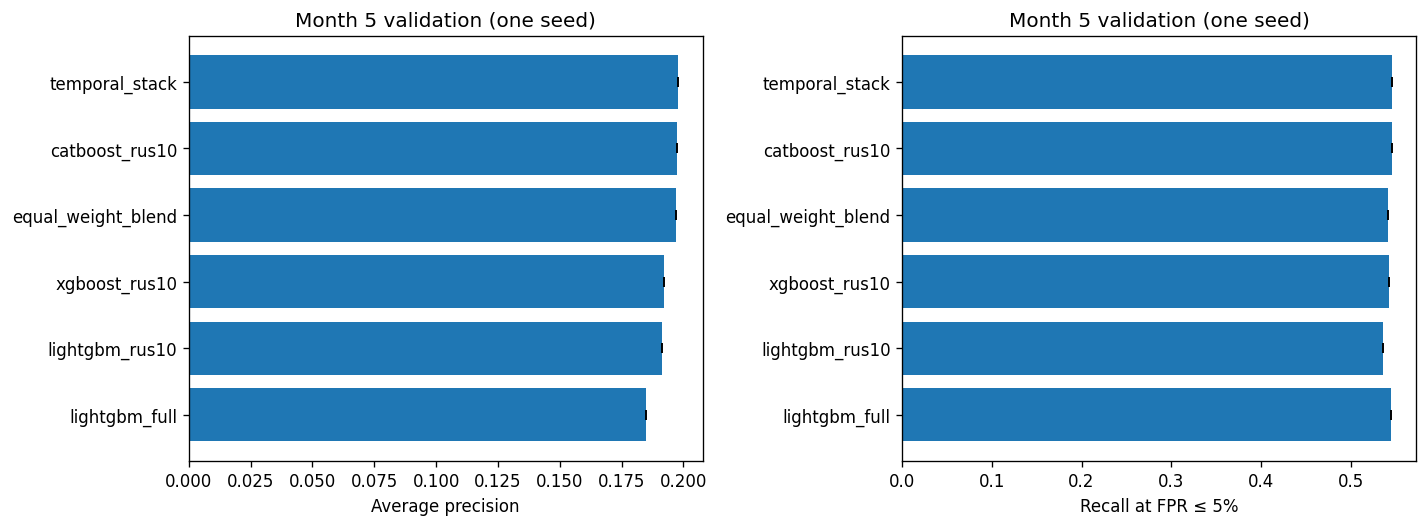

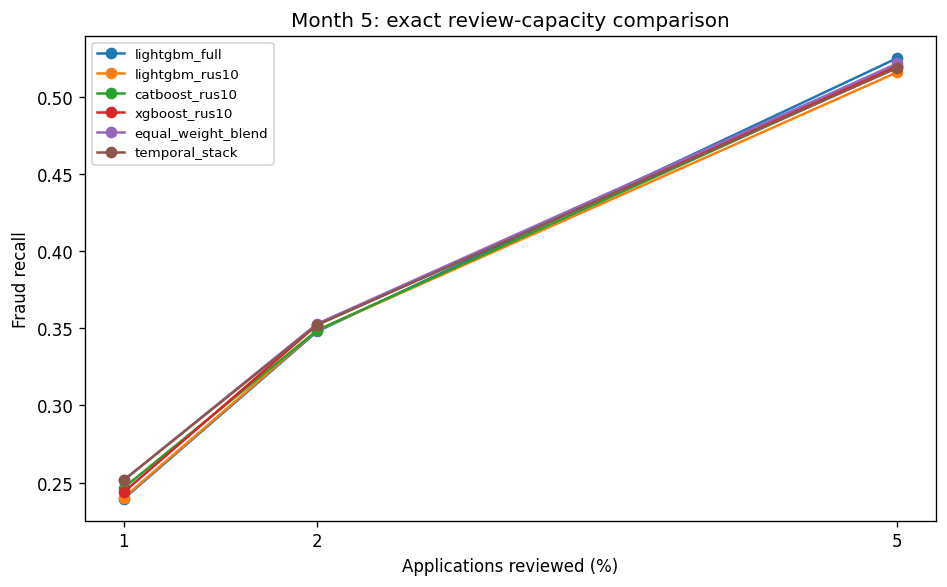

Saved results: /content/drive/MyDrive/BT4012_grp_proj/results/temporal_stacking/temporal_stack_20261115T195110Z_f62256
Saved artifacts: /content/drive/MyDrive/BT4012_grp_proj/artifacts/temporal_stacking/temporal_stack_20261115T195110Z_f62256
Test months evaluated: False


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
positions = np.arange(len(summary))
for ax, mean_col, sd_col, label in [
    (axes[0], 'ap_mean', 'ap_std', 'Average precision'),
    (axes[1], 'recall_at_fpr_mean', 'recall_at_fpr_std', 'Recall at FPR ≤ 5%'),
]:
    ax.barh(positions, summary[mean_col], xerr=summary[sd_col].fillna(0), capsize=3)
    ax.set_yticks(positions, summary['candidate'])
    ax.invert_yaxis()
    ax.set_xlabel(label)
    ax.set_title('Month 5 validation' + (' (one seed)' if len(SEEDS) == 1 else ' (mean ± seed SD)'))
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'stacking_comparison.png', bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
for candidate, frame in capacity_summary.groupby('candidate', sort=False):
    ax.plot(100 * frame['capacity'], frame['recall_mean'], marker='o', label=candidate)
ax.set(xlabel='Applications reviewed (%)', ylabel='Fraud recall',
       title='Month 5: exact review-capacity comparison')
ax.set_xticks([100 * value for value in REVIEW_CAPACITIES])
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'stacking_review_capacity.png', bbox_inches='tight')
plt.show()
plt.close(fig)

expected_fits = len(SEEDS) * (len(FOLDS) * len(BASE_ORDER) + len(BASE_ORDER) + 1)
assert len(fit_records) == expected_fits
assert len(metrics) == 6 * len(SEEDS)
run_info['status'] = 'complete'
run_info['completed_base_fits'] = len(fit_records)
run_info['completed_meta_fits'] = len(seed_manifests)
run_info['highest_validation_ap_candidate'] = summary.iloc[0]['candidate']
write_json('run_info.json', run_info)
print('Saved results:', RESULTS_DIR)
print('Saved artifacts:', ARTIFACTS_DIR)
print('Test months evaluated: False')


## 10. Decide whether stacking earns its complexity

Record whether the stack improves AP over CatBoost, whether recall at 5% FPR agrees, and whether fraud capture improves at 1/2/5% review budgets. Compare with the equal-weight blend: if a simple fixed average matches or beats the stack, there is no evidence here that the learned combination earns its extra training complexity.

A positive single-seed result is preliminary. Repeat with `[42, 43, 44]` before relying on a small gain. If stacking fails, report that outcome and retain the stronger individual model; do not keep inventing new meta-models to fit month 5.

**Limitations to report:** reused month-5 development selection, hyperparameters chosen before this run using month 5, one seed by default, shared preparation feature schema, expanding-window score-distribution mismatch, and an assumed absence of label delay. The forward folds keep base-model fitting earlier than their prediction month; they do not make the complete historical development process a nested unbiased backtest.

**Reloading:** load each saved final base pipeline from `stack_models.json`, predict on prepared features in `FEATURES` order, place positive-class scores in a dataframe with columns exactly `BASE_ORDER`, then pass it to the saved meta pipeline. Do not scale the scores yourself: StandardScaler is already in that pipeline. Each seed defines a separate stack. Keep compatible dependency versions and load only trusted joblib files.

**Share:** executed notebook, `stacking_summary.csv`, `paired_stack_comparisons.csv`, `capacity_summary.csv`, `meta_coefficients.csv`, figures and `run_info.json`. Keep the large `artifacts/` directory out of Git. Final test months remain reserved until the comparison and decision policies are frozen. Flagged fraud labels do not establish fraud prevented or monetary savings. Acknowledge AI assistance according to module requirements.
